# VQC Variation: H gate before each CNOT

Same circuit as before, but with an **H (Hadamard) gate on the control qubit right before every CNOT**.

Circuit layout:
1. **Encoding layer**: `Ry(x_i)` on each qubit
2. **Entangling layer**: H(0) + CX(0,1) -> H(1) + CX(1,2) (the *remote* CX) -> H(2) + CX(2,3)
3. **Trainable layer**: `Ry(theta_i)` on each qubit
4. **Measure** qubits 0 and 1 only (to match the paper's baseline circuit)

The H gate puts the control qubit into a mix of |0> and |1>, so the CNOT creates more entanglement.

In [1]:
# Install dependencies
%pip install --quiet "qiskit[visualization]"
from qiskit import QuantumCircuit
import numpy as np

Note: you may need to restart the kernel to use updated packages.


In [2]:
n = 4  # number of qubits

# Input data values x0..x3 (angles in radians) - change these to try other inputs
x = [0.1, 0.5, 1.0, 1.5]

# Trainable parameters theta0..theta3 - a training loop would normally update these
theta = [0.3, 0.7, 1.2, 0.9]

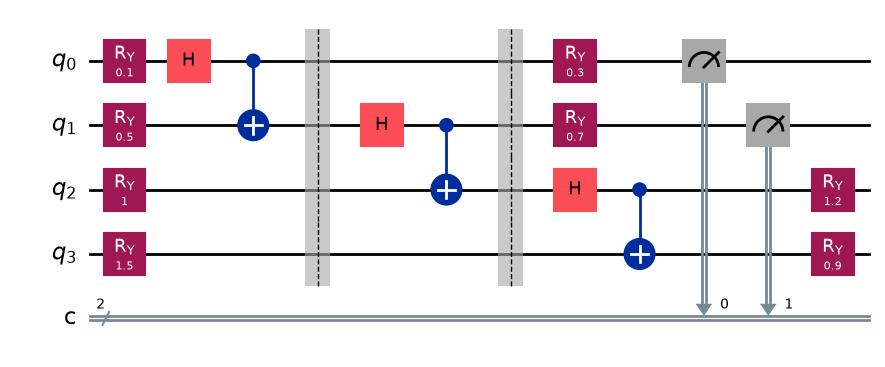

In [3]:
vqc2 = QuantumCircuit(n, 2)  # 4 qubits, 2 classical bits (only q0, q1 are measured, per the paper)

# 1) Encoding layer: Ry(x_i) on every qubit
for i in range(n):
    vqc2.ry(x[i], i)

# 2) Entangling layer (NEW: H gate on the control qubit before each CNOT)
vqc2.h(0)
vqc2.cx(0, 1)

vqc2.barrier()   # barriers just mark the remote-CX so it stands out in the drawing
vqc2.h(1)
vqc2.cx(1, 2)    # the remote-CX (red box in the figure)
vqc2.barrier()

vqc2.h(2)
vqc2.cx(2, 3)

# 3) Trainable layer: Ry(theta_i) on every qubit
for i in range(n):
    vqc2.ry(theta[i], i)

# 4) Measure only qubits 0 and 1 (matches the paper's baseline circuit)
vqc2.measure([0, 1], [0, 1])

vqc2.draw("mpl")

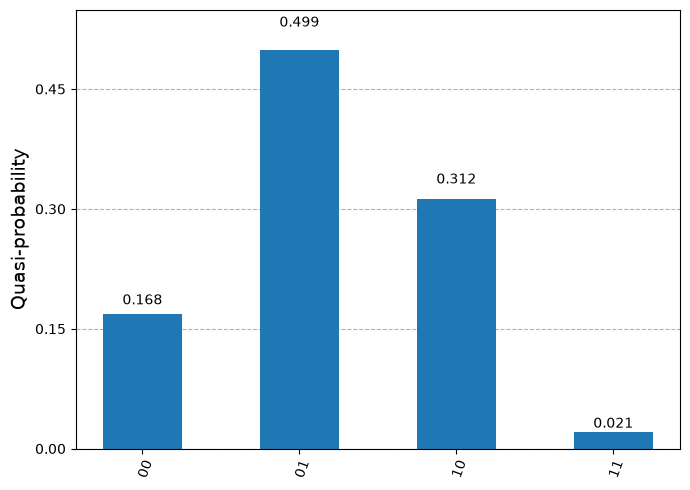

In [4]:
from qiskit.providers.basic_provider import BasicSimulator
from qiskit import transpile

simulator = BasicSimulator()
vqc2_t = transpile(vqc2, simulator)
job = simulator.run(vqc2_t, shots=1000)
results = job.result()
counts_before = results.get_counts(vqc2_t)  # H after Ry (original)

from qiskit.visualization import plot_distribution
plot_distribution(counts_before)

# VQC Variation: H gate before Ry (instead of after)

Same idea, but now the **H gate on the control qubit comes before the `Ry(x_i)` encoding gate**, instead of after it.

Circuit layout:
1. **Entangling/encoding layer** (per qubit, in order): H(0) -> Ry(x0) -> CX(0,1) -> H(1) -> Ry(x1) -> CX(1,2) -> H(2) -> Ry(x2) -> CX(2,3)
2. **Trainable layer**: `Ry(theta_i)` on each qubit
3. **Measure** qubits 0 and 1 only (to match the paper's baseline circuit)

Putting H before Ry means the qubit is already in a superposition when the data-dependent rotation is applied, instead of being rotated first and then mixed by H.

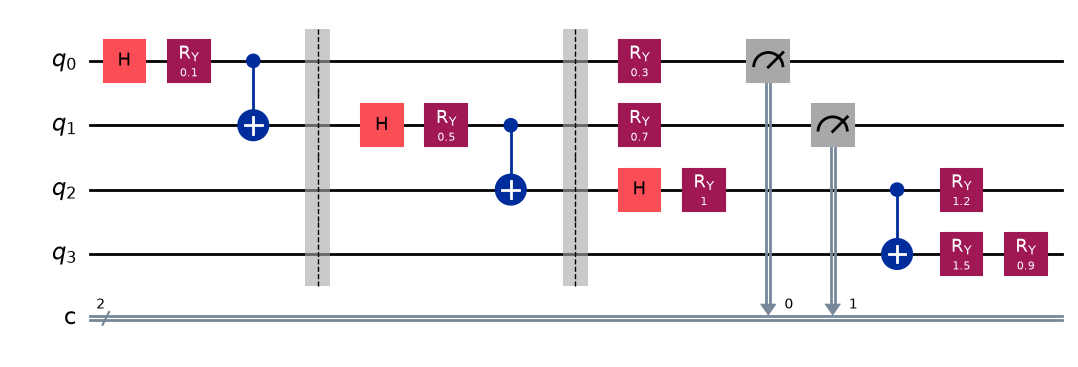

In [5]:
vqc3 = QuantumCircuit(n, 2)  # 4 qubits, 2 classical bits (only q0, q1 are measured, per the paper)

# 1) Entangling/encoding layer: H on the control qubit BEFORE Ry(x_i), then CX
vqc3.h(0)
vqc3.ry(x[0], 0)
vqc3.cx(0, 1)

vqc3.barrier()   # barriers just mark the remote-CX so it stands out in the drawing
vqc3.h(1)
vqc3.ry(x[1], 1)
vqc3.cx(1, 2)    # the remote-CX (red box in the figure)
vqc3.barrier()

vqc3.h(2)
vqc3.ry(x[2], 2)
vqc3.cx(2, 3)

# the last qubit has no outgoing CX, so just apply its encoding Ry
vqc3.ry(x[3], 3)

# 2) Trainable layer: Ry(theta_i) on every qubit
for i in range(n):
    vqc3.ry(theta[i], i)

# 3) Measure only qubits 0 and 1 (matches the paper's baseline circuit)
vqc3.measure([0, 1], [0, 1])

vqc3.draw("mpl")

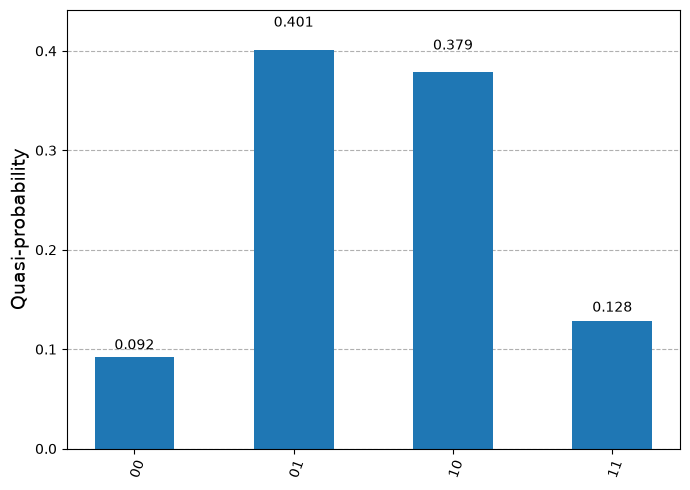

In [6]:
vqc3_t = transpile(vqc3, simulator)
job = simulator.run(vqc3_t, shots=1000)
results = job.result()
counts_after = results.get_counts(vqc3_t)  # H before Ry (new)

plot_distribution(counts_after)

# Comparison: H before Ry vs. H after Ry

Side-by-side comparison of the measurement distributions for the two variations.

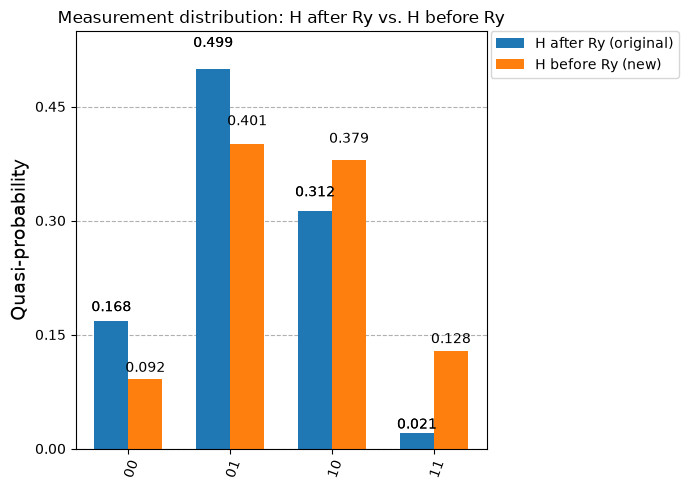

In [7]:
plot_distribution(
    [counts_before, counts_after],
    legend=["H after Ry (original)", "H before Ry (new)"],
    title="Measurement distribution: H after Ry vs. H before Ry",
)

## Measurement, softmax, and loss (Eq. 4-6 from the paper)

- Measure ⟨Z⟩ on qubit 0 and qubit 1 → two numbers
- Softmax → probability of class 0 and class 1
- Loss = cross-entropy

![Softmax, cross-entropy loss, and cost function (Eq. 4-6 from the paper)](images/paper_eq4-6_softmax_crossentropy.png)

**Softmax (Eq. 4):**
$$p(z)_j = \frac{e^{z_j}}{\sum_l e^{z_l}}$$

where $z$ is a vector (here, the two ⟨Z⟩ measurement values).

**Cross-entropy loss (Eq. 5):**
$$\mathcal{L}(y, p) = -\frac{1}{N} \sum_{i=0}^{N-1} \sum_{k=0}^{K-1} y_{i,k} \log p_{i,k}$$

**Cost function (Eq. 6):**
$$C(\theta) = \mathcal{L}(y, p(f(X, \theta)))$$

where $\theta$ are the circuit parameters, $y$ the true labels, and $X$ the dataset. The objective is to minimize $C(\theta)$ over $\theta$.

In [8]:
# Build the gate matrices and circuit unitaries from the equations above, in code
import numpy as np
from qiskit.quantum_info import Statevector

I2 = np.eye(2)
X = np.array([[0, 1], [1, 0]])
H_mat = (1 / np.sqrt(2)) * np.array([[1, 1], [1, -1]])

def Ry(t):
    c, s = np.cos(t / 2), np.sin(t / 2)
    return np.array([[c, -s], [s, c]])

def op_on_qubit(mat, qubit, n=4):
    """Embed a 1-qubit matrix on `qubit` into the full n-qubit space (qiskit little-endian order:
    qubit 0 is the least-significant / innermost factor in the Kronecker product)."""
    ops = [mat if i == qubit else I2 for i in range(n)]
    full = ops[0]
    for m in ops[1:]:
        full = np.kron(m, full)
    return full

def cx(control, target, n=4):
    """n-qubit CNOT matrix built from projectors, matching qiskit's qubit ordering."""
    P0 = np.array([[1, 0], [0, 0]])
    P1 = np.array([[0, 0], [0, 1]])
    return op_on_qubit(P0, control, n) + op_on_qubit(P1, control, n) @ op_on_qubit(X, target, n)

def ry_layer(angles, n=4):
    full = np.eye(2 ** n)
    for i, a in enumerate(angles):
        full = op_on_qubit(Ry(a), i, n) @ full
    return full

# Variation A -- H before CNOT (vqc2): Ry(x) layer, then H+CX chain, then Ry(theta) layer.
# Gates are left-multiplied in chronological order, so the first-applied gate ends up
# rightmost next to the |0000> ket.
U_vqc2 = ry_layer(x)
U_vqc2 = op_on_qubit(H_mat, 0) @ U_vqc2
U_vqc2 = cx(0, 1) @ U_vqc2
U_vqc2 = op_on_qubit(H_mat, 1) @ U_vqc2
U_vqc2 = cx(1, 2) @ U_vqc2
U_vqc2 = op_on_qubit(H_mat, 2) @ U_vqc2
U_vqc2 = cx(2, 3) @ U_vqc2
U_vqc2 = ry_layer(theta) @ U_vqc2

# Variation B -- H before Ry (vqc3): H -> Ry(x_i) -> CX per qubit, qubit 3 has no outgoing CX.
U_vqc3 = np.eye(2 ** n)
U_vqc3 = op_on_qubit(H_mat, 0) @ U_vqc3
U_vqc3 = op_on_qubit(Ry(x[0]), 0) @ U_vqc3
U_vqc3 = cx(0, 1) @ U_vqc3
U_vqc3 = op_on_qubit(H_mat, 1) @ U_vqc3
U_vqc3 = op_on_qubit(Ry(x[1]), 1) @ U_vqc3
U_vqc3 = cx(1, 2) @ U_vqc3
U_vqc3 = op_on_qubit(H_mat, 2) @ U_vqc3
U_vqc3 = op_on_qubit(Ry(x[2]), 2) @ U_vqc3
U_vqc3 = cx(2, 3) @ U_vqc3
U_vqc3 = op_on_qubit(Ry(x[3]), 3) @ U_vqc3
U_vqc3 = ry_layer(theta) @ U_vqc3

zero_state = np.zeros(2 ** n)
zero_state[0] = 1
psi_vqc2 = U_vqc2 @ zero_state
psi_vqc3 = U_vqc3 @ zero_state

# Cross-check against qiskit by stripping the measurements off the built circuits
vqc2_u = vqc2.remove_final_measurements(inplace=False)
vqc3_u = vqc3.remove_final_measurements(inplace=False)
psi_vqc2_qiskit = Statevector(vqc2_u).data
psi_vqc3_qiskit = Statevector(vqc3_u).data

print("vqc2 matches qiskit:", np.allclose(psi_vqc2, psi_vqc2_qiskit, atol=1e-8))
print("vqc3 matches qiskit:", np.allclose(psi_vqc3, psi_vqc3_qiskit, atol=1e-8))

vqc2 matches qiskit: True
vqc3 matches qiskit: True


## Updated circuit diagrams (measuring q0, q1 only)

Both variations now match the paper's baseline circuit: q2 and q3 still take part in the entangling chain, but only q0 and q1 are measured.

vqc2 -- H before each CNOT


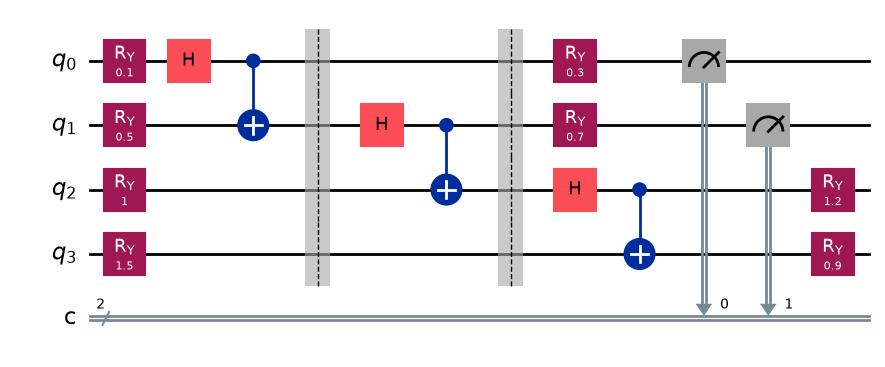

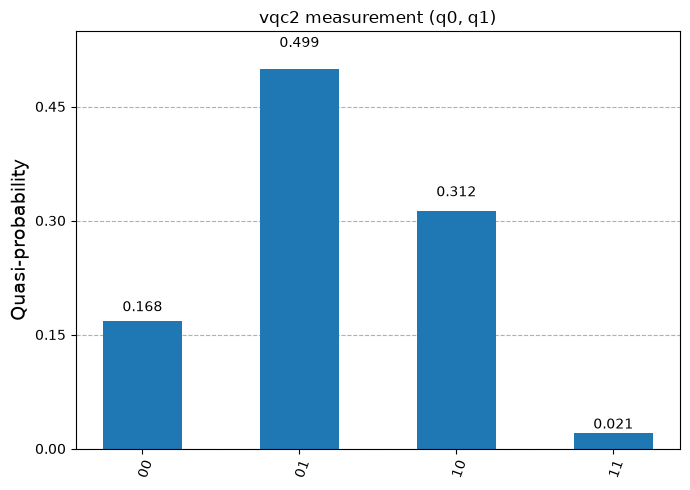

  <Z> (q0, q1)   = [-0.04   0.334]
  softmax (Eq. 4)    = [0.40757484 0.59242516]
  cross-entropy (Eq. 5, y_true=[1. 0.]) = 0.8975

vqc3 -- H before Ry


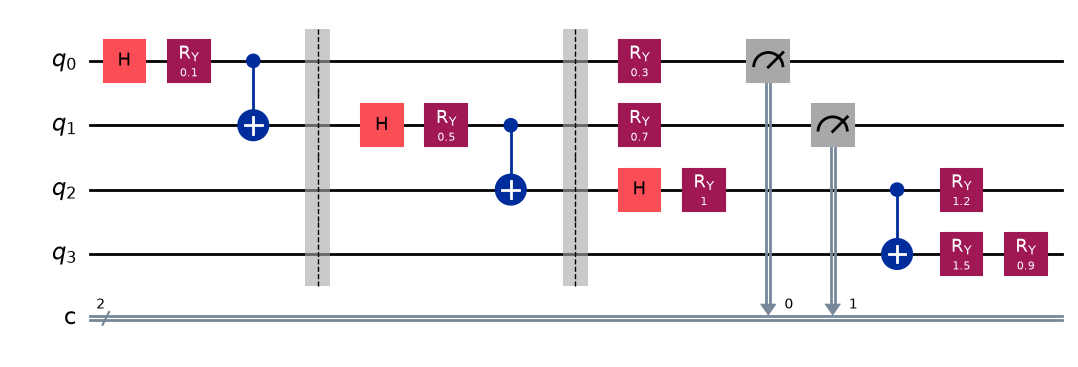

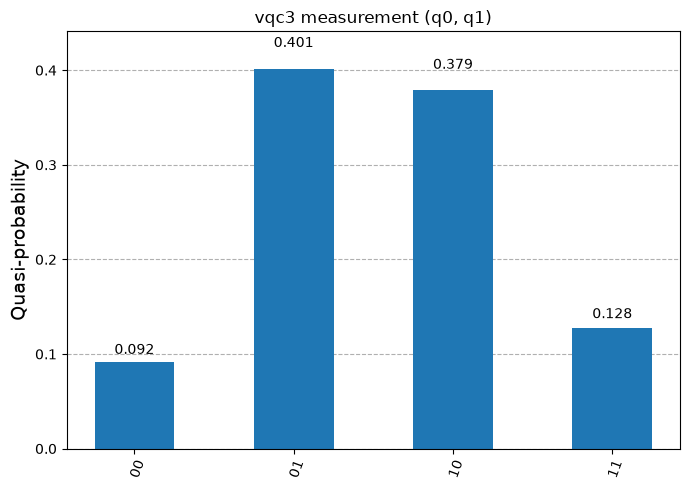

  <Z> (q0, q1)       = [-0.058 -0.014]
  softmax (Eq. 4)    = [0.48900177 0.51099823]
  cross-entropy (Eq. 5, y_true=[1. 0.]) = 0.7154


In [9]:
def expectation_z(counts, bit_index):
    """<Z> on classical bit `bit_index`, from a counts dict keyed by bitstrings c1c0."""
    total = sum(counts.values())
    return sum(c * (1 - 2 * int(bitstring[-1 - bit_index])) for bitstring, c in counts.items()) / total

def softmax(z):
    e = np.exp(z - np.max(z))
    return e / e.sum()

def cross_entropy(y_true, p):
    return -np.sum(y_true * np.log(p))


y_true = np.array([1.0, 0.0])

print("vqc2 -- H before each CNOT")
display(vqc2.draw("mpl"))
display(plot_distribution(counts_before, title="vqc2 measurement (q0, q1)"))

z_vqc2 = np.array([expectation_z(counts_before, 0), expectation_z(counts_before, 1)])
p_vqc2 = softmax(z_vqc2)
loss_vqc2 = cross_entropy(y_true, p_vqc2)
print(f"  <Z> (q0, q1)   = {z_vqc2}")
print(f"  softmax (Eq. 4)    = {p_vqc2}")
print(f"  cross-entropy (Eq. 5, y_true={y_true}) = {loss_vqc2:.4f}")

print()
print("vqc3 -- H before Ry")
display(vqc3.draw("mpl"))
display(plot_distribution(counts_after, title="vqc3 measurement (q0, q1)"))

z_vqc3 = np.array([expectation_z(counts_after, 0), expectation_z(counts_after, 1)])
p_vqc3 = softmax(z_vqc3)
loss_vqc3 = cross_entropy(y_true, p_vqc3)
print(f"  <Z> (q0, q1)       = {z_vqc3}")
print(f"  softmax (Eq. 4)    = {p_vqc3}")
print(f"  cross-entropy (Eq. 5, y_true={y_true}) = {loss_vqc3:.4f}")

## Training theta with the parameter-shift rule

So far `theta` was just a fixed guess. "Training" means adjusting `theta` so the circuit's
output (after softmax) gets closer to the assumed true label `y_true`.

Since the circuit is run on a simulator (not auto-differentiated), we use the
**parameter-shift rule**: for a gate like `Ry(theta_i)`, the exact derivative of any
expectation value with respect to `theta_i` is

$$\frac{\partial \langle Z \rangle}{\partial \theta_i} = \frac{\langle Z \rangle(\theta_i + \pi/2) - \langle Z \rangle(\theta_i - \pi/2)}{2}$$

i.e. run the circuit twice more per parameter, shifted by $\pm\pi/2$, and the slope falls out exactly
(no finite-difference approximation needed). The softmax+cross-entropy part is then combined in with
the standard chain-rule shortcut $\partial \mathcal{L}/\partial z_j = p_j - y_j$.

This trains `vqc2` (H before CNOT) on the single toy example `x`, `y_true` already defined above.

epoch  0  loss=0.8486  p=[0.428 0.572]  theta=[0.161 0.806 1.181 0.888]


epoch  1  loss=0.8372  p=[0.433 0.567]  theta=[0.031 0.93  1.174 0.884]
epoch  2  loss=0.7656  p=[0.465 0.535]  theta=[-0.097  1.039  1.179  0.901]
epoch  3  loss=0.7032  p=[0.495 0.505]  theta=[-0.215  1.159  1.188  0.896]
epoch  4  loss=0.6247  p=[0.535 0.465]  theta=[-0.319  1.276  1.193  0.909]


epoch  5  loss=0.5999  p=[0.549 0.451]  theta=[-0.398  1.387  1.199  0.909]


epoch  6  loss=0.5919  p=[0.553 0.447]  theta=[-0.488  1.498  1.208  0.906]


epoch  7  loss=0.5019  p=[0.605 0.395]  theta=[-0.567  1.588  1.209  0.907]
epoch  8  loss=0.4718  p=[0.624 0.376]  theta=[-0.633  1.683  1.212  0.898]
epoch  9  loss=0.4688  p=[0.626 0.374]  theta=[-0.704  1.775  1.211  0.885]
epoch 10  loss=0.4570  p=[0.633 0.367]  theta=[-0.759  1.86   1.214  0.881]


epoch 11  loss=0.4256  p=[0.653 0.347]  theta=[-0.803  1.935  1.214  0.883]


epoch 12  loss=0.4375  p=[0.646 0.354]  theta=[-0.846  2.005  1.223  0.881]


epoch 13  loss=0.4099  p=[0.664 0.336]  theta=[-0.886  2.066  1.237  0.881]
epoch 14  loss=0.4092  p=[0.664 0.336]  theta=[-0.924  2.131  1.229  0.875]

theta before training: [0.3, 0.7, 1.2, 0.9]
theta after training:  [-0.924  2.131  1.229  0.875]
loss: 0.8486 -> 0.4092


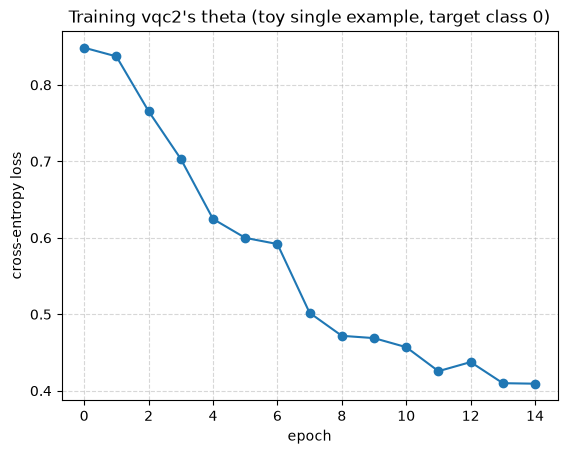

In [10]:
import matplotlib.pyplot as plt

def build_vqc2(x_vals, theta_vals):
    qc = QuantumCircuit(n, 2)
    for i in range(n):
        qc.ry(x_vals[i], i)
    qc.h(0); qc.cx(0, 1)
    qc.h(1); qc.cx(1, 2)
    qc.h(2); qc.cx(2, 3)
    for i in range(n):
        qc.ry(theta_vals[i], i)
    qc.measure([0, 1], [0, 1])
    return qc

def run_z(theta_vals, shots=1000):
    """Build the circuit, run it, and return <Z> on (q0, q1)."""
    qc = build_vqc2(x, theta_vals)
    qc_t = transpile(qc, simulator)
    job = simulator.run(qc_t, shots=shots)
    counts = job.result().get_counts(qc_t)
    return np.array([expectation_z(counts, 0), expectation_z(counts, 1)])

def forward(theta_vals):
    z = run_z(theta_vals)
    p = softmax(z)
    return z, p

def param_shift_grad(theta_vals, y_target):
    """Exact gradient of the softmax-cross-entropy loss w.r.t. every theta_i."""
    _, p = forward(theta_vals)
    dL_dz = p - y_target  # softmax + cross-entropy combined gradient
    grad = np.zeros_like(theta_vals)
    for i in range(len(theta_vals)):
        shifted_plus = theta_vals.copy();  shifted_plus[i] += np.pi / 2
        shifted_minus = theta_vals.copy(); shifted_minus[i] -= np.pi / 2
        dz_dtheta_i = (run_z(shifted_plus) - run_z(shifted_minus)) / 2
        grad[i] = dL_dz @ dz_dtheta_i
    return grad

# Gradient descent training loop (toy single-example training)
theta_trained = np.array(theta, dtype=float).copy()
lr = 0.5
epochs = 15
loss_history = []

for epoch in range(epochs):
    z, p = forward(theta_trained)
    loss = cross_entropy(y_true, p)
    loss_history.append(loss)
    grad = param_shift_grad(theta_trained, y_true)
    theta_trained -= lr * grad
    print(f"epoch {epoch:2d}  loss={loss:.4f}  p={np.round(p, 3)}  theta={np.round(theta_trained, 3)}")

print()
print("theta before training:", theta)
print("theta after training: ", np.round(theta_trained, 3))
print(f"loss: {loss_history[0]:.4f} -> {loss_history[-1]:.4f}")

plt.plot(loss_history, marker="o")
plt.xlabel("epoch")
plt.ylabel("cross-entropy loss")
plt.title("Training vqc2's theta (toy single example, target class 0)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

add remote cnot.
difference between 2 and 4 measurement .
purpose of r theta 3 and 4 ancilla .
A VQC with alternating global and local layers. A global layer contains CX gates between different QPUs whereas a local layer only contains CX between qubits residing in the same QPU.

add remote cnot gates

## Remote CNOT: a CX gate between two separate QPUs

Right now the "remote-CX" in `vqc2`/`vqc3` is just `qc.cx(1, 2)`. That's fine on one
simulator, but if q1 and q2 actually sat on two different QPUs, there'd be no wire
connecting them -- you can't apply a normal 2-qubit gate across that gap.

The fix: share one entangled pair of extra ("ancilla") qubits between the two QPUs,
do a couple of simple local gates and measurements, then send the two measurement
results over as plain classical bits (just 0s and 1s -- easy to send). Using those
bits to apply a small correction gate on each side makes the end result come out
*exactly* the same as a normal CX between q1 and q2, even though they never touched.

Steps:
1. Make a Bell pair: `anc_a` (QPU A) and `anc_b` (QPU B).
2. QPU A: `CX(control, anc_a)`, then measure `anc_a` -> bit `m_a`. Send `m_a` to QPU B.
3. QPU B: if `m_a` is 1, flip `anc_b`. Then `CX(anc_b, target)`, `H(anc_b)`, measure
   `anc_b` -> bit `m_b`. Send `m_b` back to QPU A.
4. QPU A: if `m_b` is 1, apply `Z` to `control`.

The randomness in `m_a`/`m_b` always cancels out, so `control` and `target` end up
exactly as if a normal CX had happened directly between them.

In [11]:
from qiskit.quantum_info import Statevector
from qiskit.circuit.library import XGate, ZGate, HGate, CXGate


def remote_cx(sv, control, target, anc_a, anc_b):
    """CX(control, target), done through ancillas anc_a (with control) and
    anc_b (with target) instead of a direct 2-qubit gate."""
    sv = sv.evolve(HGate(), [anc_a])
    sv = sv.evolve(CXGate(), [anc_a, anc_b])    # share a Bell pair
    sv = sv.evolve(CXGate(), [control, anc_a])
    m_a, sv = sv.measure([anc_a])
    if int(m_a[0]):
        sv = sv.evolve(XGate(), [anc_a])    # reset anc_a to |0> so it can be reused
        sv = sv.evolve(XGate(), [anc_b])
    sv = sv.evolve(CXGate(), [anc_b, target])
    sv = sv.evolve(HGate(), [anc_b])
    m_b, sv = sv.measure([anc_b])
    if int(m_b[0]):
        sv = sv.evolve(ZGate(), [control])
        sv = sv.evolve(XGate(), [anc_b])    # reset anc_b to |0> so it can be reused
    return sv


def z_expect(sv, qubit):
    """<Z> on one qubit, same convention as expectation_z() above but from a statevector."""
    return sum(p * (1 - 2 * int(bits[-1 - qubit])) for bits, p in sv.probabilities_dict().items())


# direct version: the usual vqc2, with cx(1, 2) done directly
qc_direct = QuantumCircuit(n)
for i in range(n):
    qc_direct.ry(x[i], i)
qc_direct.h(0); qc_direct.cx(0, 1)
qc_direct.h(1); qc_direct.cx(1, 2)
qc_direct.h(2); qc_direct.cx(2, 3)
for i in range(n):
    qc_direct.ry(theta[i], i)

sv_direct = Statevector.from_label("0" * n).evolve(qc_direct)
z_direct = [z_expect(sv_direct, 0), z_expect(sv_direct, 1)]

# remote version: same circuit, but cx(1, 2) replaced by remote_cx with 2 ancillas (q4, q5)
n_tot = n + 2
prep = QuantumCircuit(n_tot)
for i in range(n):
    prep.ry(x[i], i)
prep.h(0); prep.cx(0, 1)
prep.h(1)

sv_remote = Statevector.from_label("0" * n_tot).evolve(prep)
sv_remote = remote_cx(sv_remote, control=1, target=2, anc_a=4, anc_b=5)

rest = QuantumCircuit(n_tot)
rest.h(2); rest.cx(2, 3)
for i in range(n):
    rest.ry(theta[i], i)
sv_remote = sv_remote.evolve(rest)
z_remote = [z_expect(sv_remote, 0), z_expect(sv_remote, 1)]

print("direct <Z0>, <Z1>:", np.round(z_direct, 6))
print("remote <Z0>, <Z1>:", np.round(z_remote, 6))
print("match:", np.allclose(z_direct, z_remote))

direct <Z0>, <Z1>: [-0.045598  0.319191]
remote <Z0>, <Z1>: [-0.045598  0.319191]
match: True


differnce between 2 and 4 measurements and purpose of r thetha 3 and 4 in 2 measurement 

## Measuring 2 qubits vs measuring all 4

Measuring only q0 and q1 gives 2 bits per shot, so only 4 possible outcomes: `00`, `01`, `10`,
`11`. Measuring all 4 qubits gives 4 bits per shot, so 16 possible outcomes -- much more detail,
but also much more to keep track of for no benefit here. The paper's circuit only needs 2 numbers
out (for a 2-class softmax), so reading just q0/q1 is enough -- q2 and q3 still take part in the
entangling gates, we just never read them out. The cell below measures all 4 qubits, then adds up
("marginalizes") the counts over q2/q3, and checks that it lands on roughly the same q0/q1
distribution as measuring 2 qubits directly.

In [12]:
from collections import defaultdict

def build_measure(measure_all):
    qc = QuantumCircuit(n, n if measure_all else 2)
    for i in range(n):
        qc.ry(x[i], i)
    qc.h(0); qc.cx(0, 1)
    qc.h(1); qc.cx(1, 2)
    qc.h(2); qc.cx(2, 3)
    for i in range(n):
        qc.ry(theta[i], i)
    if measure_all:
        qc.measure(range(n), range(n))
    else:
        qc.measure([0, 1], [0, 1])
    return qc

qc_2 = transpile(build_measure(measure_all=False), simulator)
qc_4 = transpile(build_measure(measure_all=True), simulator)
counts_2 = simulator.run(qc_2, shots=1000).result().get_counts()
counts_4 = simulator.run(qc_4, shots=1000).result().get_counts()

print(f"measuring q0,q1 only: {len(counts_2)} possible outcomes -> {counts_2}")
print(f"measuring all 4:      {len(counts_4)} possible outcomes seen")

# marginalize the 4-qubit counts down to just q0,q1 (bitstring is c3c2c1c0)
marginal = defaultdict(int)
for bitstring, c in counts_4.items():
    marginal[bitstring[-2:]] += c

print("4-qubit counts marginalized to q0,q1:", dict(marginal))
print("compare to measuring q0,q1 directly: ", counts_2)

measuring q0,q1 only: 4 possible outcomes -> {'01': 507, '00': 168, '10': 307, '11': 18}
measuring all 4:      15 possible outcomes seen
4-qubit counts marginalized to q0,q1: {'01': 539, '10': 295, '00': 147, '11': 19}
compare to measuring q0,q1 directly:  {'01': 507, '00': 168, '10': 307, '11': 18}


## Purpose of theta_2 and theta_3 when only q0, q1 are measured

Since q2 and q3 are never measured, what are their trainable angles `theta_2`, `theta_3` even
doing? In this circuit the trainable `Ry` layer runs *after* all the entangling gates, so rotating
q2/q3 at that point has nothing left to carry the change back to q0/q1 -- there's no gate after it
to connect them. The check below confirms this directly: changing `theta_2` and `theta_3` to
completely different values doesn't move `<Z0>`/`<Z1>` at all. So in this 2-measurement version,
`theta_2` and `theta_3` are dead weights -- they'd only matter if q2/q3 were measured too, or if
the trainable layer came *before* the entangling layer instead of after.

In [13]:
def z_expect_exact(theta_vals):
    qc = QuantumCircuit(n)
    for i in range(n):
        qc.ry(x[i], i)
    qc.h(0); qc.cx(0, 1)
    qc.h(1); qc.cx(1, 2)
    qc.h(2); qc.cx(2, 3)
    for i in range(n):
        qc.ry(theta_vals[i], i)
    sv = Statevector.from_label("0" * n).evolve(qc)
    return [z_expect(sv, 0), z_expect(sv, 1)]

theta_base = [0.3, 0.7, 1.2, 0.9]       # original theta_2, theta_3
theta_changed = [0.3, 0.7, 5.5, -2.1]   # wildly different theta_2, theta_3, same theta_0, theta_1

print("theta_2, theta_3 = 1.2, 0.9  -> <Z0>, <Z1> =", np.round(z_expect_exact(theta_base), 6))
print("theta_2, theta_3 = 5.5, -2.1 -> <Z0>, <Z1> =", np.round(z_expect_exact(theta_changed), 6))
print("identical:", np.allclose(z_expect_exact(theta_base), z_expect_exact(theta_changed)))

theta_2, theta_3 = 1.2, 0.9  -> <Z0>, <Z1> = [-0.045598  0.319191]
theta_2, theta_3 = 5.5, -2.1 -> <Z0>, <Z1> = [-0.045598  0.319191]
identical: True


In this single layer, θ2 and θ3 come after all the CX gates, and qubits 2 and 3 are never measured. Nothing connects them to qubits 0 and 1 afterwards, so in this one layer by itself, θ2 and θ3 have zero effect on the output.

They only become useful because this layer is repeated 10 times. In the next layer, the CX ladder runs again and carries the effect of θ2 and θ3 back into qubits 0 and 1. So:

Last layer: θ2 and θ3 are wasted.
Every earlier layer: θ2 and θ3 matter, because a later CX passes their effect along.

A VQC with alternating global and local layers. A global layer contains CX gates between different QPUs whereas a local layer only contains CX between qubits residing in the same QPU.

## A VQC with alternating global and local layers

Split the 4 qubits into two QPUs: QPU A = {q0, q1}, QPU B = {q2, q3}. A **local** layer only
uses CX gates inside one QPU -- `CX(0,1)` on A, `CX(2,3)` on B -- so it's a normal, cheap gate.
A **global** layer uses a CX *between* the two QPUs -- `CX(1,2)`, crossing the boundary -- so
it's done with the `remote_cx` protocol from above instead of a direct gate. The circuit below
repeats, for a few layers: trainable `Ry` -> local layer -> global layer. The same 2 ancilla
qubits are reused for every global layer (they get reset back to `|0>` after each use).

In [14]:
def build_alternating_vqc(x_vals, theta_layers, anc_a=4, anc_b=5):
    """Encode x, then repeat: trainable Ry -> local layer (CX within each QPU) ->
    global layer (remote CX across the QPU boundary, q1 <-> q2)."""
    n_tot = len(x_vals) + 2
    sv = Statevector.from_label("0" * n_tot)

    encode = QuantumCircuit(n_tot)
    for i in range(len(x_vals)):
        encode.ry(x_vals[i], i)
    sv = sv.evolve(encode)

    for theta_vals in theta_layers:
        layer = QuantumCircuit(n_tot)
        for i in range(len(theta_vals)):
            layer.ry(theta_vals[i], i)
        layer.cx(0, 1)   # local layer: QPU A
        layer.cx(2, 3)   # local layer: QPU B
        sv = sv.evolve(layer)
        sv = remote_cx(sv, control=1, target=2, anc_a=anc_a, anc_b=anc_b)  # global layer
    return sv


# demo: 3 alternating layers of random trainable angles
rng = np.random.default_rng(0)
theta_layers = rng.uniform(0, 2 * np.pi, size=(3, n))

sv_alt = build_alternating_vqc(x, theta_layers)
z_alt = [z_expect(sv_alt, 0), z_expect(sv_alt, 1)]


qc_ref = QuantumCircuit(n)
for i in range(n):
    qc_ref.ry(x[i], i)
for theta_vals in theta_layers:
    for i in range(n):
        qc_ref.ry(theta_vals[i], i)
    qc_ref.cx(0, 1); qc_ref.cx(2, 3); qc_ref.cx(1, 2)
sv_ref = Statevector.from_label("0" * n).evolve(qc_ref)
z_ref = [z_expect(sv_ref, 0), z_expect(sv_ref, 1)]

print("alternating (remote global CX): <Z0>, <Z1> =", np.round(z_alt, 6))
print("reference   (direct global CX): <Z0>, <Z1> =", np.round(z_ref, 6))
print("match:", np.allclose(z_alt, z_ref))

alternating (remote global CX): <Z0>, <Z1> = [ 0.752206 -0.468424]
reference   (direct global CX): <Z0>, <Z1> = [ 0.752206 -0.468424]
match: True


## Drawing the alternating-layer circuit

`remote_cx` above works on a `Statevector` directly (with the measurement + correction done in
plain Python), so there's no single `QuantumCircuit` to draw for it. The cell below rebuilds the
same alternating-layers circuit as an actual `QuantumCircuit` -- using `if_test` to show the
classically-controlled fix-up gates -- purely so it can be drawn. (It's for the picture only;
`BasicSimulator` can't run circuits with classical control flow like this.)

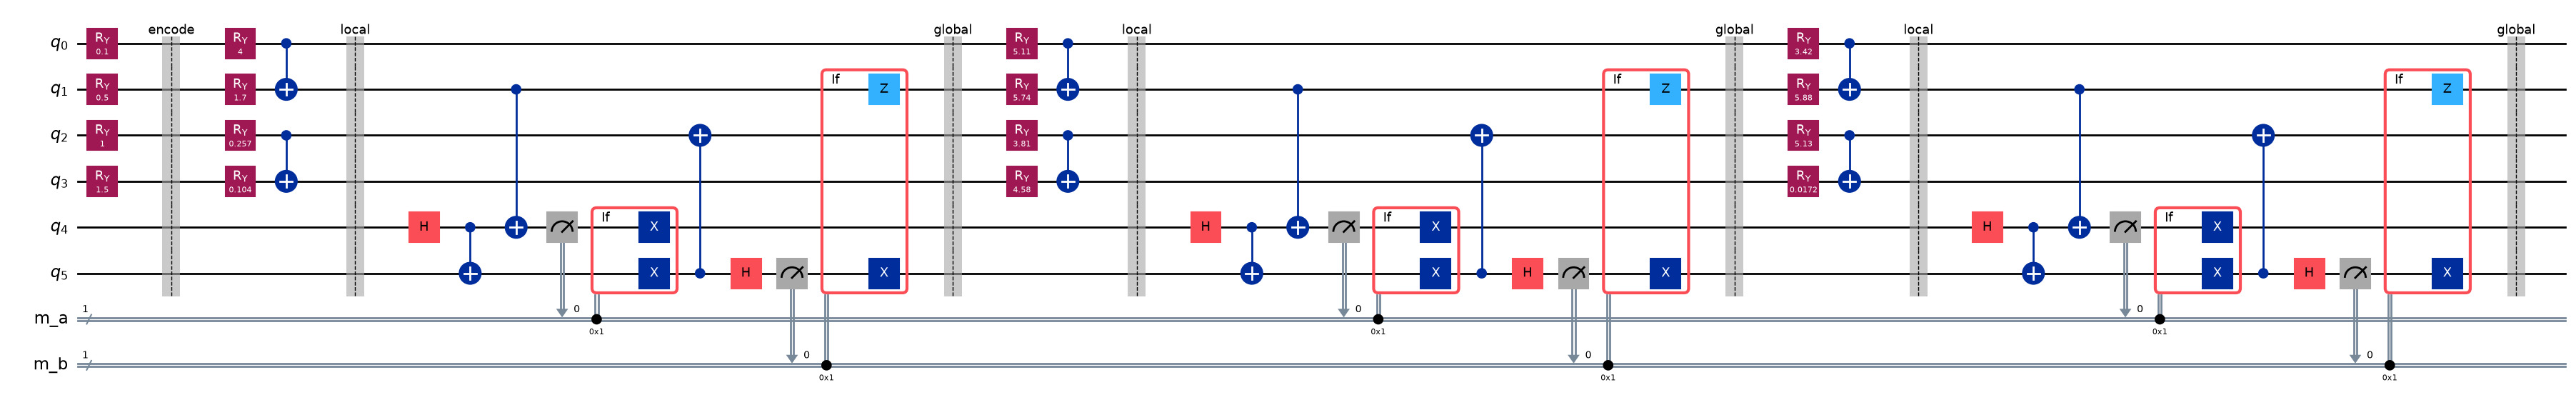

In [15]:
from qiskit import ClassicalRegister


def remote_cx_circuit(qc, control, target, anc_a, anc_b, m_a, m_b):
    """Same remote_cx protocol as above, written as circuit gates (for drawing only)."""
    qc.h(anc_a)
    qc.cx(anc_a, anc_b)
    qc.cx(control, anc_a)
    qc.measure(anc_a, m_a)
    with qc.if_test((m_a, 1)):
        qc.x(anc_a)
        qc.x(anc_b)
    qc.cx(anc_b, target)
    qc.h(anc_b)
    qc.measure(anc_b, m_b)
    with qc.if_test((m_b, 1)):
        qc.z(control)
        qc.x(anc_b)


qc_alt = QuantumCircuit(n + 2, name="alternating global/local VQC")
m_a = ClassicalRegister(1, "m_a")
m_b = ClassicalRegister(1, "m_b")
qc_alt.add_register(m_a)
qc_alt.add_register(m_b)

for i in range(n):
    qc_alt.ry(x[i], i)
qc_alt.barrier(label="encode")

for theta_vals in theta_layers:
    for i in range(n):
        qc_alt.ry(theta_vals[i], i)
    qc_alt.cx(0, 1); qc_alt.cx(2, 3)   # local layer
    qc_alt.barrier(label="local")
    remote_cx_circuit(qc_alt, control=1, target=2, anc_a=4, anc_b=5, m_a=m_a, m_b=m_b)  # global layer
    qc_alt.barrier(label="global")

qc_alt.draw("mpl", fold=-1)

## Global/local layer diagram, drawn in the paper's style

Same ansatz as above (2 QPUs, 4 qubits), drawn the way the paper draws it: a **Global Layer**
block containing a local-CX step then a cross-QPU global-CX step, a trainable `Ry` layer, a
**Local Layer** block (local CX only), another trainable `Ry` layer, then measuring q0/q1 --
with curly-bracket QPU groupings on the right, matching the reference figure.

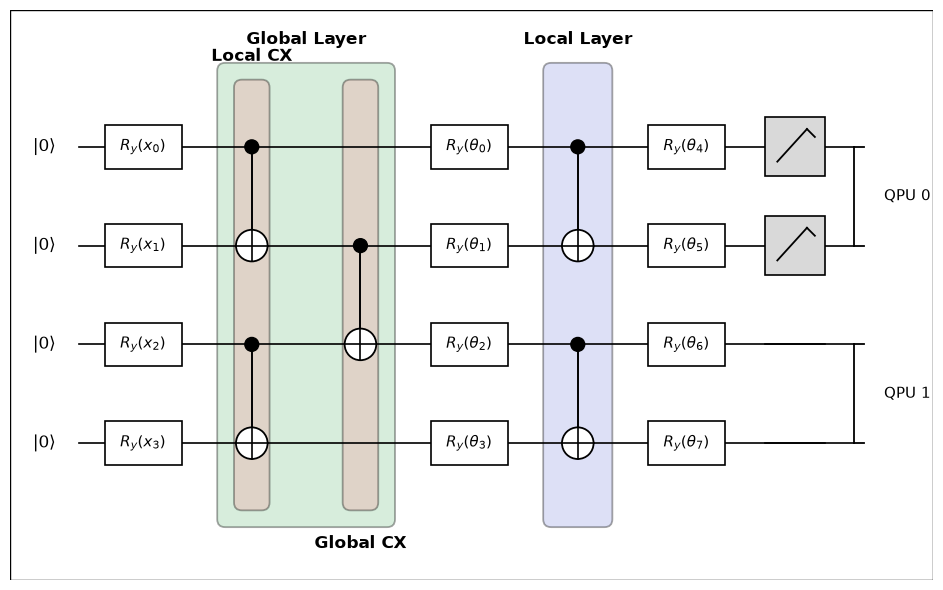

In [16]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle, Circle
from matplotlib.lines import Line2D


def draw_global_local_vqc(n=4, qpu_sizes=(2, 2), measured=(0, 1), figsize=(11, 6)):
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_aspect("equal")

    y = {i: i for i in range(n)}  # q0 at top (y=0), increasing downward after inversion

    x_ket, x_ry0 = 0.0, 1.0
    x_lcx1, x_gcx = 2.1, 3.2
    x_ry1 = 4.3
    x_lcx2 = 5.4
    x_ry2 = 6.5
    x_meas = 7.6
    x_brace, x_label = 8.2, 8.5

    # local CX pairs: within each QPU
    local_pairs = []
    start = 0
    for size in qpu_sizes:
        for i in range(start, start + size - 1, 2):
            local_pairs.append((i, i + 1))
        start += size

    # global CX pairs: across QPU boundaries
    global_pairs = []
    acc = 0
    for size in qpu_sizes[:-1]:
        acc += size
        global_pairs.append((acc - 1, acc))

    def bg_box(x0, x1, color, label=None, label_above=True, pad=0.28):
        top_edge = -0.5 - pad
        bottom_edge = (n - 1) + 0.5 + pad
        box = FancyBboxPatch(
            (x0 - pad, top_edge), (x1 - x0) + 2 * pad, bottom_edge - top_edge,
            boxstyle="round,pad=0,rounding_size=0.08",
            linewidth=1.3, edgecolor="black", facecolor=color, alpha=0.35, zorder=0,
        )
        ax.add_patch(box)
        if label:
            ly = top_edge - 0.15 if label_above else bottom_edge + 0.25
            ax.text((x0 + x1) / 2, ly, label, ha="center", va="bottom" if label_above else "top",
                     fontsize=12, fontweight="bold")

    bg_box(x_lcx1, x_gcx, "#8fce9b", label="Global Layer", pad=0.35)
    bg_box(x_lcx1, x_lcx1, "#f0a3a3", label="Local CX", label_above=True, pad=0.18)
    bg_box(x_gcx, x_gcx, "#f0a3a3", label="Global CX", label_above=False, pad=0.18)
    bg_box(x_lcx2, x_lcx2, "#9fa8e8", label="Local Layer", pad=0.35)

    for i in range(n):
        ax.add_line(Line2D([x_ket + 0.35, x_meas + 0.6], [y[i], y[i]], color="black", lw=1.2, zorder=1))
        ax.text(x_ket, y[i], r"$|0\rangle$", ha="center", va="center", fontsize=12, zorder=3)

    def gate_box(x, yi, label, w=0.78, h=0.44, fc="white"):
        rect = Rectangle((x - w / 2, yi - h / 2), w, h, facecolor=fc, edgecolor="black",
                          linewidth=1.2, zorder=3)
        ax.add_patch(rect)
        ax.text(x, yi, label, ha="center", va="center", fontsize=11, zorder=4)

    for i in range(n):
        gate_box(x_ry0, y[i], rf"$R_y(x_{{{i}}})$")

    def draw_cx(x, control, target):
        yc, yt = y[control], y[target]
        ax.add_line(Line2D([x, x], [yc, yt], color="black", lw=1.4, zorder=2))
        ax.add_patch(Circle((x, yc), 0.07, facecolor="black", edgecolor="black", zorder=3))
        r = 0.16
        ax.add_patch(Circle((x, yt), r, facecolor="white", edgecolor="black", linewidth=1.3, zorder=3))
        ax.add_line(Line2D([x - r, x + r], [yt, yt], color="black", lw=1.2, zorder=4))
        ax.add_line(Line2D([x, x], [yt - r, yt + r], color="black", lw=1.2, zorder=4))

    for c, t in local_pairs:
        draw_cx(x_lcx1, c, t)
    for c, t in global_pairs:
        draw_cx(x_gcx, c, t)

    n_theta1 = n
    for i in range(n):
        gate_box(x_ry1, y[i], rf"$R_y(\theta_{{{i}}})$")

    for c, t in local_pairs:
        draw_cx(x_lcx2, c, t)

    for i in range(n):
        gate_box(x_ry2, y[i], rf"$R_y(\theta_{{{n_theta1 + i}}})$")

    for i in range(n):
        if i in measured:
            rect = Rectangle((x_meas - 0.3, y[i] - 0.3), 0.6, 0.6, facecolor="#d9d9d9",
                              edgecolor="black", linewidth=1.2, zorder=3)
            ax.add_patch(rect)
            ax.plot([x_meas - 0.18, x_meas + 0.12], [y[i] + 0.15, y[i] - 0.18],
                    color="black", lw=1.3, zorder=4)
            ax.plot([x_meas + 0.12, x_meas + 0.2], [y[i] - 0.18, y[i] - 0.1],
                    color="black", lw=1.3, zorder=4)
        else:
            ax.add_line(Line2D([x_meas - 0.3, x_meas + 0.3], [y[i], y[i]], color="black", lw=1.2, zorder=1))

    start = 0
    for qi, size in enumerate(qpu_sizes):
        top, bot = y[start], y[start + size - 1]
        mid = (top + bot) / 2
        ax.add_line(Line2D([x_brace, x_brace], [top, bot], color="black", lw=1.3, zorder=3))
        ax.add_line(Line2D([x_brace, x_brace + 0.1], [top, top], color="black", lw=1.3, zorder=3))
        ax.add_line(Line2D([x_brace, x_brace + 0.1], [bot, bot], color="black", lw=1.3, zorder=3))
        ax.text(x_label, mid, f"QPU {qi}", ha="left", va="center", fontsize=11)
        start += size

    ax.relim()
    ax.autoscale_view()
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    pad_x, pad_y = 0.3, 0.3
    new_xlim = (xlim[0] - pad_x, xlim[1] + pad_x)
    new_ylim = (ylim[0] - pad_y, ylim[1] + pad_y)
    border = Rectangle((new_xlim[0], new_ylim[0]), new_xlim[1] - new_xlim[0], new_ylim[1] - new_ylim[0],
                        fill=False, edgecolor="black", linewidth=1.0, zorder=5)
    ax.add_patch(border)
    ax.set_xlim(new_xlim)
    ax.set_ylim(new_ylim)
    ax.invert_yaxis()
    ax.axis("off")

    fig.tight_layout()
    return fig


draw_global_local_vqc(n=4, qpu_sizes=(2, 2), measured=(0, 1))
plt.show()

## Difference: previous circuit vs. the global/local layered circuit

One simple comparison: the original `vqc2` circuit (single entangling chain, one `Ry` layer)
against the new global/local layered circuit above (Global Layer -> `Ry` -> Local Layer -> `Ry`).
The global CX is run directly here (not through `remote_cx`) since it's just for comparing
measurement distributions, and we already showed the two give identical results.

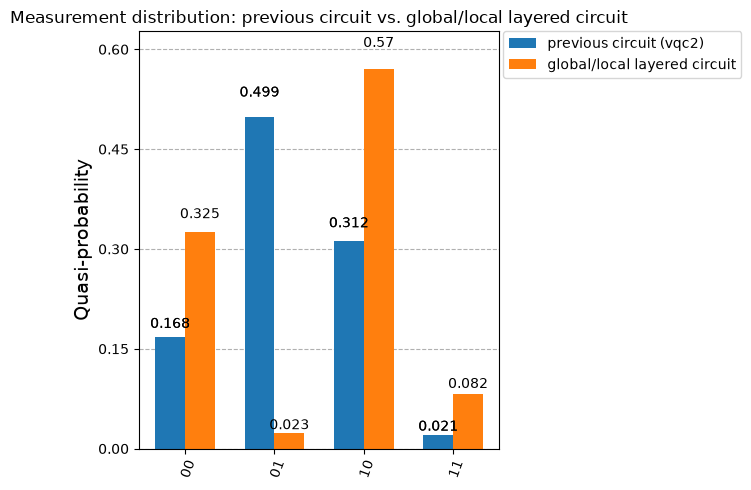

In [17]:
def build_global_local_circuit(x_vals, theta_vals):
    """Runnable version of the Global Layer -> Ry -> Local Layer -> Ry circuit above
    (global CX done directly here, just for comparing distributions)."""
    qc = QuantumCircuit(n, 2)
    for i in range(n):
        qc.ry(x_vals[i], i)
    qc.cx(0, 1); qc.cx(2, 3)      # Global Layer: local CX
    qc.cx(1, 2)                   # Global Layer: global CX (crosses the QPU boundary)
    for i in range(n):
        qc.ry(theta_vals[i], i)
    qc.cx(0, 1); qc.cx(2, 3)      # Local Layer
    for i in range(n):
        qc.ry(theta_vals[n + i], i)
    qc.measure([0, 1], [0, 1])
    return qc


theta_full = theta + theta  # reuse the same 4 values for both Ry layers (8 total)
qc_global_local = transpile(build_global_local_circuit(x, theta_full), simulator)
counts_global_local = simulator.run(qc_global_local, shots=1000).result().get_counts()

plot_distribution(
    [counts_before, counts_global_local],
    legend=["previous circuit (vqc2)", "global/local layered circuit"],
    title="Measurement distribution: previous circuit vs. global/local layered circuit",
)

qooa : tsp mixer 
remote cnot gate vs normal
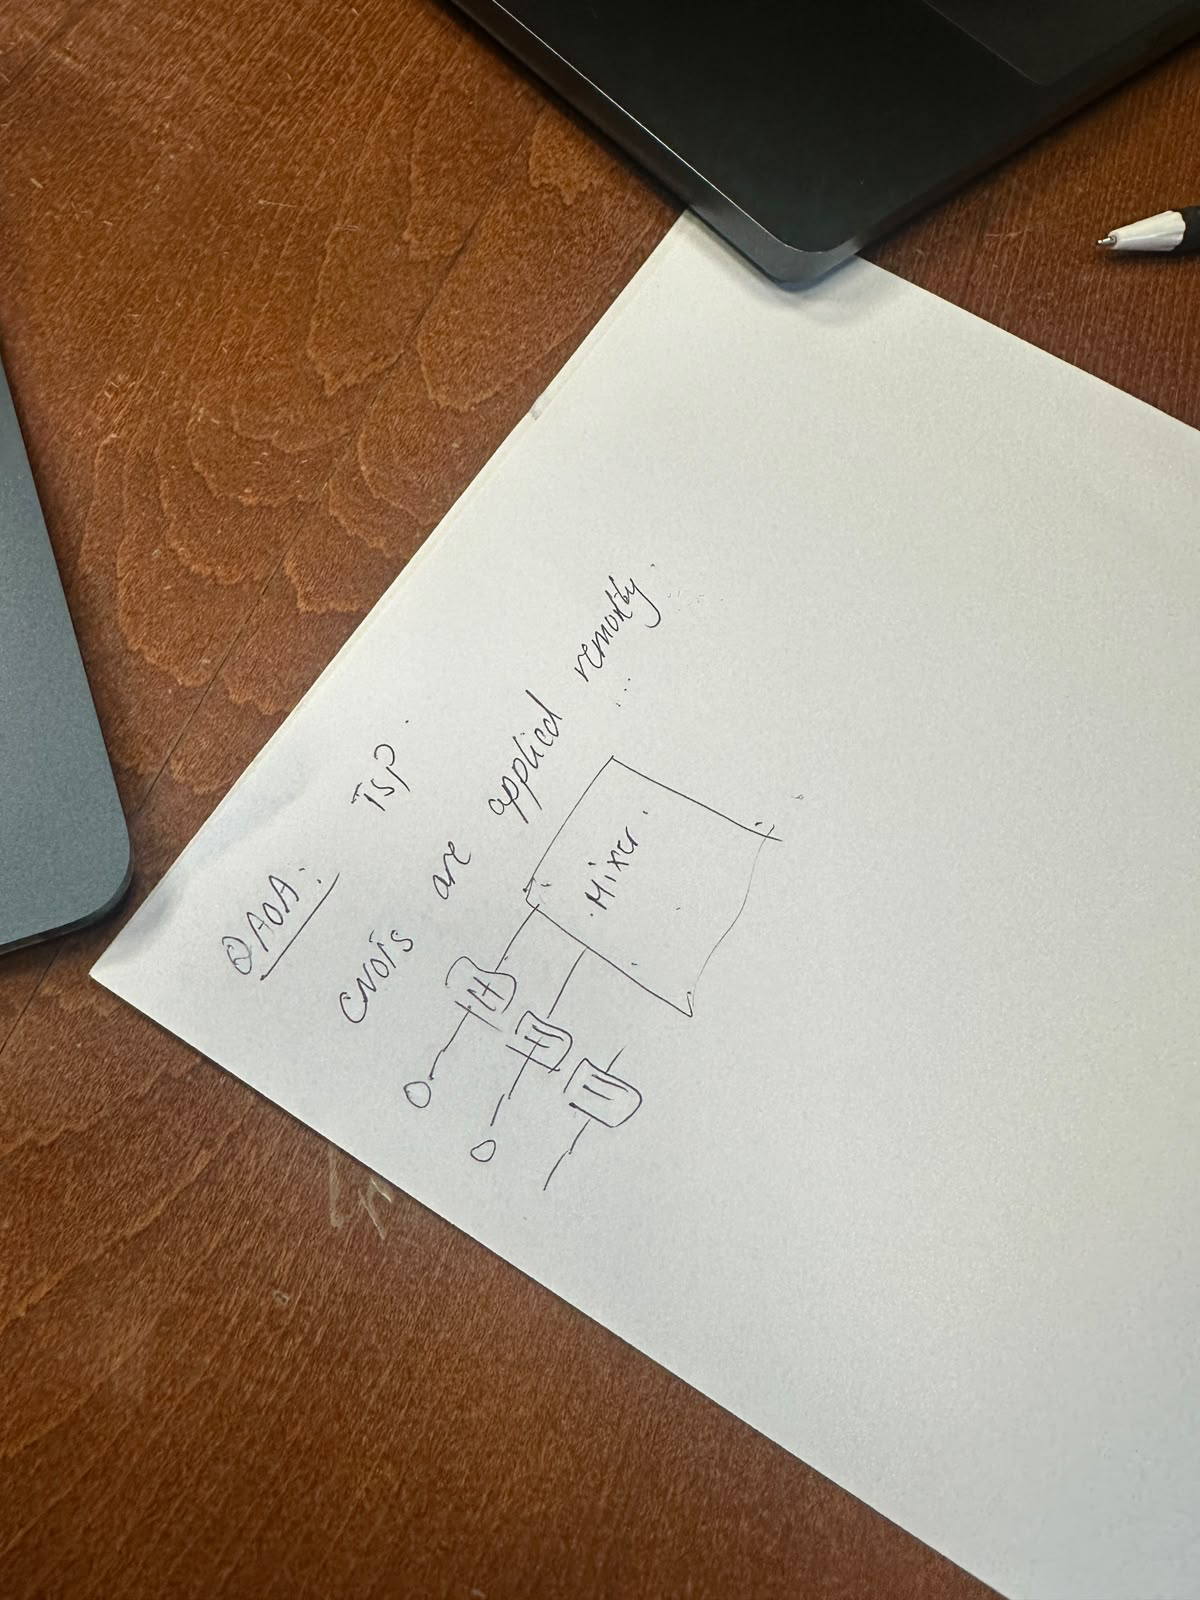

## QAOA for TSP: layout

**TSP** (Travelling Salesman Problem): given a set of cities and the distances between them, find the shortest round trip that visits every city exactly once and returns to the start.
tsp notes : find min dist . hamiltonian cycle(a node that circle backs to it)
greedy aproach 
brute force appraoch - o(n-1!)
DYNAMIC PROG  approach O(n^n)

**QAOA** (Quantum Approximate Optimization Algorithm): a short, trainable circuit that alternates a *cost* layer (turns the problem into phase rotations, strength set by `gamma`) with a *mixer* layer (spreads the amplitude across candidate solutions, strength set by `beta`), so that measuring the circuit is more likely to return a low-cost (short) tour.

What follows, step by step:
1. A tiny 3-city TSP instance (city 0 fixed as the start) encoded as 4 qubits -- one per (city, time-step) pair.
2. The tour cost plus the "visit every city/time-step exactly once" penalties, written as a QUBO and converted into Z / ZZ rotation angles.
3. One QAOA layer (p=1): H on every qubit, the cost layer built from CNOT-RZ-CNOT (these are the CNOTs the note above wants applied *remotely*), then a simple mixer layer.
4. A quick simulation to check the circuit runs and see which tours it favours.

This first version uses ordinary local CNOTs for the cost layer. The next step is swapping those CNOTs for the `remote_cx()` teleportation gate built earlier in this notebook.

qoao notes : variational  circuits are designed for noisy quan computer systems 
qoao is a famous variational circuit
draws inspo from quantum annealing 

In [18]:
# 1) & 2): tiny 3-city TSP (city 0 fixed as start) as a QUBO on 4 qubits
# q0 = city1@t1, q1 = city2@t1, q2 = city1@t2, q3 = city2@t2
dist = {(0, 1): 2, (0, 2): 3, (1, 2): 1}  # symmetric distances between cities
def d(a, b):
    return dist[(a, b)] if a < b else dist[(b, a)]

q = {(1, 1): 0, (2, 1): 1, (1, 2): 2, (2, 2): 3}
n_qaoa = 4

h = {i: 0.0 for i in range(n_qaoa)}
J = {}
def add_J(i, j, val):
    key = (min(i, j), max(i, j))
    J[key] = J.get(key, 0.0) + val

# tour cost: start -> t1, t1 -> t2 (cross terms), t2 -> start
for city in (1, 2):
    h[q[(city, 1)]] += d(0, city)
    h[q[(city, 2)]] += d(0, city)
add_J(q[(1, 1)], q[(2, 2)], d(1, 2))
add_J(q[(2, 1)], q[(1, 2)], d(2, 1))

# one-hot penalties: each city visited once, each time-step filled once
P = 6.0
for a, b in [(q[(1, 1)], q[(1, 2)]), (q[(2, 1)], q[(2, 2)]),
             (q[(1, 1)], q[(2, 1)]), (q[(1, 2)], q[(2, 2)])]:
    h[a] += -P
    h[b] += -P
    add_J(a, b, 2 * P)

# QUBO (x in {0,1}) -> Ising rotation angles, using x_i = (1 - Z_i) / 2
a_coef = {i: -h[i] / 2 for i in range(n_qaoa)}
for (i, j), val in J.items():
    a_coef[i] += -val / 4
    a_coef[j] += -val / 4
b_coef = {(i, j): val / 4 for (i, j), val in J.items()}


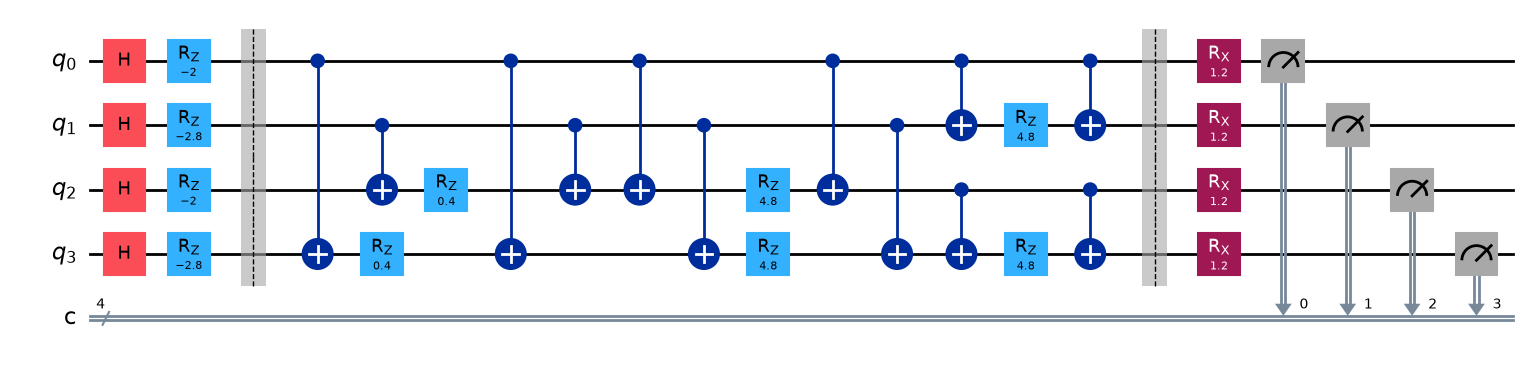

In [19]:
# 3) one QAOA layer (p = 1): H -> cost layer (CNOT-RZ-CNOT) -> mixer layer
def qaoa_tsp_circuit(gamma, beta):
    qc = QuantumCircuit(n_qaoa, n_qaoa)
    qc.h(range(n_qaoa))                     # equal superposition over all bitstrings

    for i in range(n_qaoa):                 # single-qubit cost rotations
        if abs(a_coef[i]) > 1e-9:
            qc.rz(2 * gamma * a_coef[i], i)
    qc.barrier()
    for (i, j), val in b_coef.items():       # two-qubit cost rotations -- the CNOTs
        qc.cx(i, j)                          # that should become remote_cx()
        qc.rz(2 * gamma * val, j)
        qc.cx(i, j)
    qc.barrier()

    for i in range(n_qaoa):                 # mixer layer
        qc.rx(2 * beta, i)

    qc.measure(range(n_qaoa), range(n_qaoa))
    return qc

qaoa_qc = qaoa_tsp_circuit(gamma=0.8, beta=0.6)
qaoa_qc.draw("mpl")


## Remote CNOT circuit diagram (QAOA-TSP cost layer)

The circuit above is the **local** version: every two-qubit gate in the cost layer is a direct
`qc.cx(i, j)`. This cell rebuilds the same cost layer as an actual drawable `QuantumCircuit`,
but every CX is replaced by `remote_cx_circuit()` (the teleportation gate defined earlier in the
"Remote CNOT" section) -- a shared ancilla Bell pair (`q4`, `q5`), two local CNOTs, two
mid-circuit measurements, and classically-controlled correction gates -- so the remote-CX
machinery is visible in the diagram instead of being a single 2-qubit gate. (It's for the
picture only; `BasicSimulator` can't run circuits with classical control flow like this.)

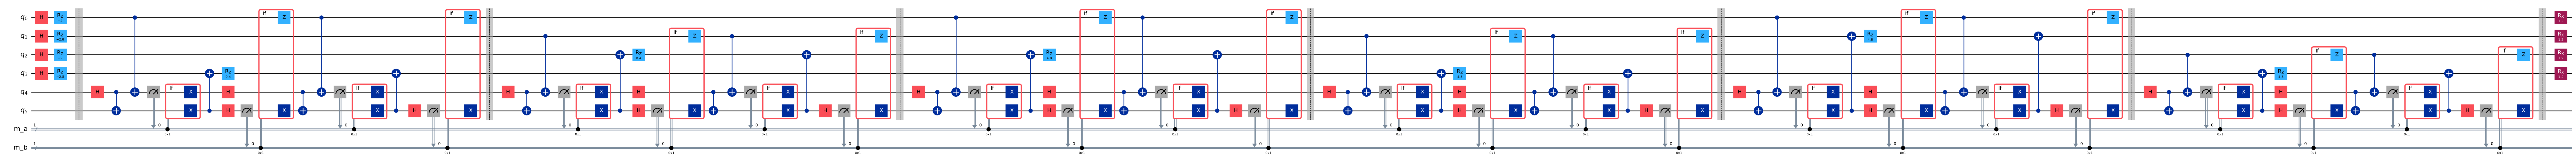

In [20]:
# remote cnot: same QAOA-TSP cost layer as qaoa_qc, but every CX is remote_cx_circuit()
# (ancilla Bell pair + classically-controlled corrections), so it draws as an actual remote circuit
def qaoa_tsp_circuit_remote(gamma, beta, anc_a=4, anc_b=5):
    qc = QuantumCircuit(n_qaoa + 2, name="QAOA-TSP (remote CNOT cost layer)")
    m_a = ClassicalRegister(1, "m_a")
    m_b = ClassicalRegister(1, "m_b")
    qc.add_register(m_a)
    qc.add_register(m_b)

    qc.h(range(n_qaoa))                     # equal superposition over all bitstrings

    for i in range(n_qaoa):                 # single-qubit cost rotations
        if abs(a_coef[i]) > 1e-9:
            qc.rz(2 * gamma * a_coef[i], i)
    qc.barrier()
    for (i, j), val in b_coef.items():       # two-qubit cost rotations, now via remote_cx_circuit
        remote_cx_circuit(qc, control=i, target=j, anc_a=anc_a, anc_b=anc_b, m_a=m_a, m_b=m_b)
        qc.rz(2 * gamma * val, j)
        remote_cx_circuit(qc, control=i, target=j, anc_a=anc_a, anc_b=anc_b, m_a=m_a, m_b=m_b)
        qc.barrier()

    for i in range(n_qaoa):                 # mixer layer
        qc.rx(2 * beta, i)

    return qc

qaoa_qc_remote = qaoa_tsp_circuit_remote(gamma=0.8, beta=0.6)
qaoa_qc_remote.draw("mpl", fold=-1)

In [21]:
# 4) run it and see which tours come out on top
qaoa_t = transpile(qaoa_qc, simulator)
qaoa_counts = simulator.run(qaoa_t, shots=2000).result().get_counts()

def tour_cost(bitstring):
    b = bitstring[::-1]  # Qiskit prints bit 0 last
    x = {q[(1, 1)]: int(b[0]), q[(2, 1)]: int(b[1]), q[(1, 2)]: int(b[2]), q[(2, 2)]: int(b[3])}
    if x[q[(1, 1)]] + x[q[(2, 1)]] != 1 or x[q[(1, 2)]] + x[q[(2, 2)]] != 1:
        return None  # not a valid one-hot assignment
    if x[q[(1, 1)]] + x[q[(1, 2)]] != 1:
        return None
    t1 = 1 if x[q[(1, 1)]] else 2
    t2 = 1 if x[q[(1, 2)]] else 2
    return d(0, t1) + d(t1, t2) + d(t2, 0)

valid = {bits: (cnt, tour_cost(bits)) for bits, cnt in qaoa_counts.items() if tour_cost(bits) is not None}
print("valid tours sampled (bitstring: shots, cost):")
for bits, (cnt, cost) in sorted(valid.items(), key=lambda kv: -kv[1][0]):
    print(f"  {bits}: {cnt} shots, cost {cost}")

best = min(d(0, 1) + d(1, 2) + d(2, 0), d(0, 2) + d(2, 1) + d(1, 0))
print("best possible tour cost (brute force):", best)


valid tours sampled (bitstring: shots, cost):
  0110: 201 shots, cost 6
  1001: 188 shots, cost 6
best possible tour cost (brute force): 6


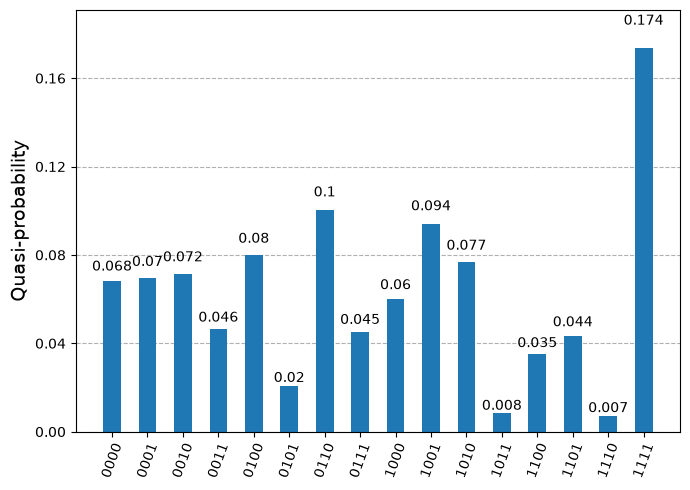

In [22]:
# graphs: full output distribution, and cost of each valid tour sampled
plot_distribution(qaoa_counts)


## Remote CNOT version of the QAOA-TSP cost layer

The circuit above builds the cost layer with ordinary local `qc.cx(i, j)` gates. Per the note,
those are the gates that should work even if qubit `i` and qubit `j` sit on two different QPUs.

So here we rebuild the same cost layer (same `a_coef` / `b_coef` angles), but every CNOT inside
it is done with `remote_cx()` (the teleportation gate from the "Remote CNOT" section above)
instead of a direct 2-qubit gate. The two ancilla qubits (q4, q5) are reused for all 6 cost-layer
pairs, since `remote_cx()` always resets them back to \|0> after each use.

This only works at the statevector level (like the earlier remote-CX check), since
`remote_cx()` needs mid-circuit measurement + classical correction, which `BasicSimulator`
doesn't support -- so we compare `<Z>` expectation values and the full probability
distribution directly, rather than sampling shots.


In [23]:
# remote version: same QAOA-TSP cost layer, but every CX goes through remote_cx()
n_tot_qaoa = n_qaoa + 2          # 4 data qubits + 2 reusable ancillas
anc_a_q, anc_b_q = 4, 5

def qaoa_tsp_statevector(gamma, beta, remote):
    prep = QuantumCircuit(n_tot_qaoa)
    prep.h(range(n_qaoa))
    for i in range(n_qaoa):
        if abs(a_coef[i]) > 1e-9:
            prep.rz(2 * gamma * a_coef[i], i)
    sv = Statevector.from_label("0" * n_tot_qaoa).evolve(prep)

    for (i, j), val in b_coef.items():
        if remote:
            sv = remote_cx(sv, control=i, target=j, anc_a=anc_a_q, anc_b=anc_b_q)
            rz = QuantumCircuit(n_tot_qaoa)
            rz.rz(2 * gamma * val, j)
            sv = sv.evolve(rz)
            sv = remote_cx(sv, control=i, target=j, anc_a=anc_a_q, anc_b=anc_b_q)
        else:
            qc = QuantumCircuit(n_tot_qaoa)
            qc.cx(i, j)
            qc.rz(2 * gamma * val, j)
            qc.cx(i, j)
            sv = sv.evolve(qc)

    mixer = QuantumCircuit(n_tot_qaoa)
    for i in range(n_qaoa):
        mixer.rx(2 * beta, i)
    sv = sv.evolve(mixer)
    return sv

sv_local = qaoa_tsp_statevector(gamma=0.8, beta=0.6, remote=False)
sv_remote = qaoa_tsp_statevector(gamma=0.8, beta=0.6, remote=True)

z_local = [z_expect(sv_local, i) for i in range(n_qaoa)]
z_remote = [z_expect(sv_remote, i) for i in range(n_qaoa)]
print("local  <Z> per data qubit:", np.round(z_local, 6))
print("remote <Z> per data qubit:", np.round(z_remote, 6))
print("match:", np.allclose(z_local, z_remote))



local  <Z> per data qubit: [-0.005976 -0.002202 -0.005976 -0.002202]
remote <Z> per data qubit: [-0.005976 -0.002202 -0.005976 -0.002202]
match: True


max |local - remote| probability difference: 9.71445146547012e-17


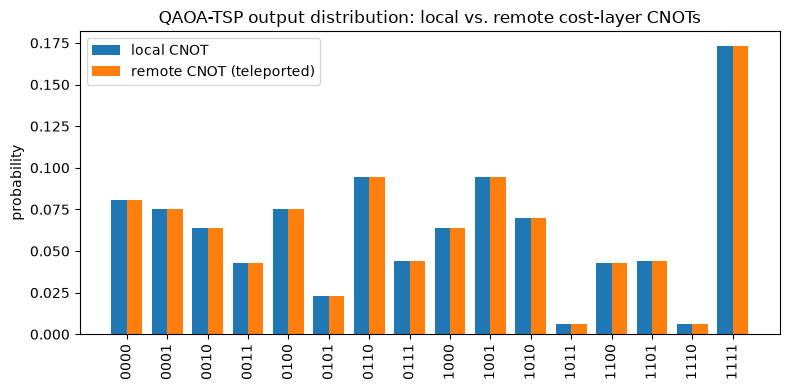

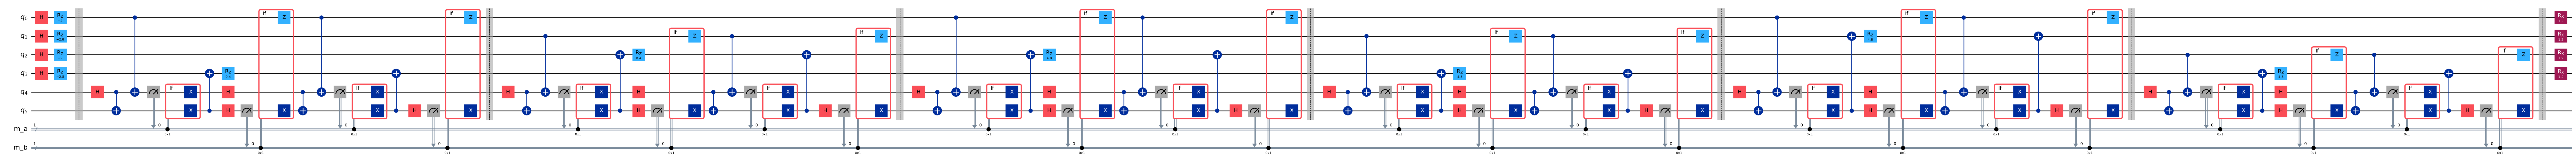

In [24]:
# compare the full local vs. remote output distributions, side by side
def marginal_dist(sv, n_data=n_qaoa):
    probs = defaultdict(float)
    for bits, p in sv.probabilities_dict().items():
        probs[bits[-n_data:]] += p
    return dict(probs)

dist_local = marginal_dist(sv_local)
dist_remote = marginal_dist(sv_remote)
max_diff = max(abs(dist_local.get(b, 0) - dist_remote.get(b, 0))
               for b in set(dist_local) | set(dist_remote))
print("max |local - remote| probability difference:", max_diff)

labels = sorted(set(dist_local) | set(dist_remote))
local_vals = [dist_local.get(b, 0) for b in labels]
remote_vals = [dist_remote.get(b, 0) for b in labels]

x = np.arange(len(labels))
width = 0.38
plt.figure(figsize=(8, 4))
plt.bar(x - width / 2, local_vals, width, label="local CNOT", color="tab:blue")
plt.bar(x + width / 2, remote_vals, width, label="remote CNOT (teleported)", color="tab:orange")
plt.xticks(x, labels, rotation=90)
plt.ylabel("probability")
plt.title("QAOA-TSP output distribution: local vs. remote cost-layer CNOTs")
plt.legend()
plt.tight_layout()
plt.show()
qaoa_qc_remote.draw("mpl", fold=-1)

## Why local and remote give an exact match, not an approximate one

`max |local - remote| probability difference` comes out at machine-precision (~1e-16), and
`match: True` every time -- this is the correct, expected result, not a coincidence of this
particular `gamma`/`beta` or this particular random seed.

The reason is in the correction step of `remote_cx()` / `remote_cx_circuit()`. Teleporting a CX
through a Bell pair leaves behind a **random** Pauli error on `control`/`target` that depends on
the two mid-circuit measurement outcomes `m_a`, `m_b` (each 50/50). Left uncorrected, the output
really would differ from a direct CX, shot to shot. But the classically-controlled `X`/`Z` fixes
(`if m_a: X(anc_a), X(anc_b)` and `if m_b: Z(control), X(anc_b)`) are exactly the Pauli operators
that undo that specific error for that specific outcome. So however `m_a`/`m_b` land, the
corrected state is algebraically identical to the direct-CX state -- the randomness cancels
every time, not just on average.

That is the entire point of gate teleportation as a protocol: it is not an approximation of a
remote CX, it reproduces one exactly, at the cost of one shared Bell pair, two local CNOTs, two
measurements, and up to two correction gates per CX. If the corrections were dropped (or applied
to the wrong qubit/condition), the match would break -- `max |local - remote|` would jump to
order-1 and `match` would read `False` about half the time, since then the leftover Pauli error
is left in the state.